# W09B B · 변수 효과·로버스트·앱

2026-10-28 · **R 커널** · A/B는 각각 새 런타임에서 독립 실행됩니다. 로딩 후 준비 셀부터 실행하고 오류를 숨기지 않습니다.

먼저 예상→손계산→실행→설명을 적습니다. 필수 L01–L06과 확장 L07–L12의 질문은 계산 기록지와 같습니다. TODO는 주석이어서 미완성 상태여도 기본 예제가 끝까지 실행됩니다. 문제용 변수와 실행 예제 변수를 구별하세요. 온라인 R·R/QMD·R Colab은 한 경로를 선택합니다. 준비 파일을 자동으로 내려받고 캐시의 MD5 동일성을 확인합니다. 공개 릴리스의 SHA-256 검증과는 구별합니다. 재시작 후 준비 셀부터 다시 실행하세요.

공통 함수 고정 버전은 **2026-fall-w09b**입니다. [입력·출력·실제 정의 바로가기](https://github.com/lunalab-ai/regre/blob/2026-fall-w09b/src/diagnostics-influence-api.md). `source()`는 함수를 읽고 `lm()`은 모형을 적합하며 진단 함수는 그 적합을 읽습니다. 공식 경주 자료는 초/마일/피트를 사용합니다. NY 단순모형과 네 변수 모형을 구분합니다.

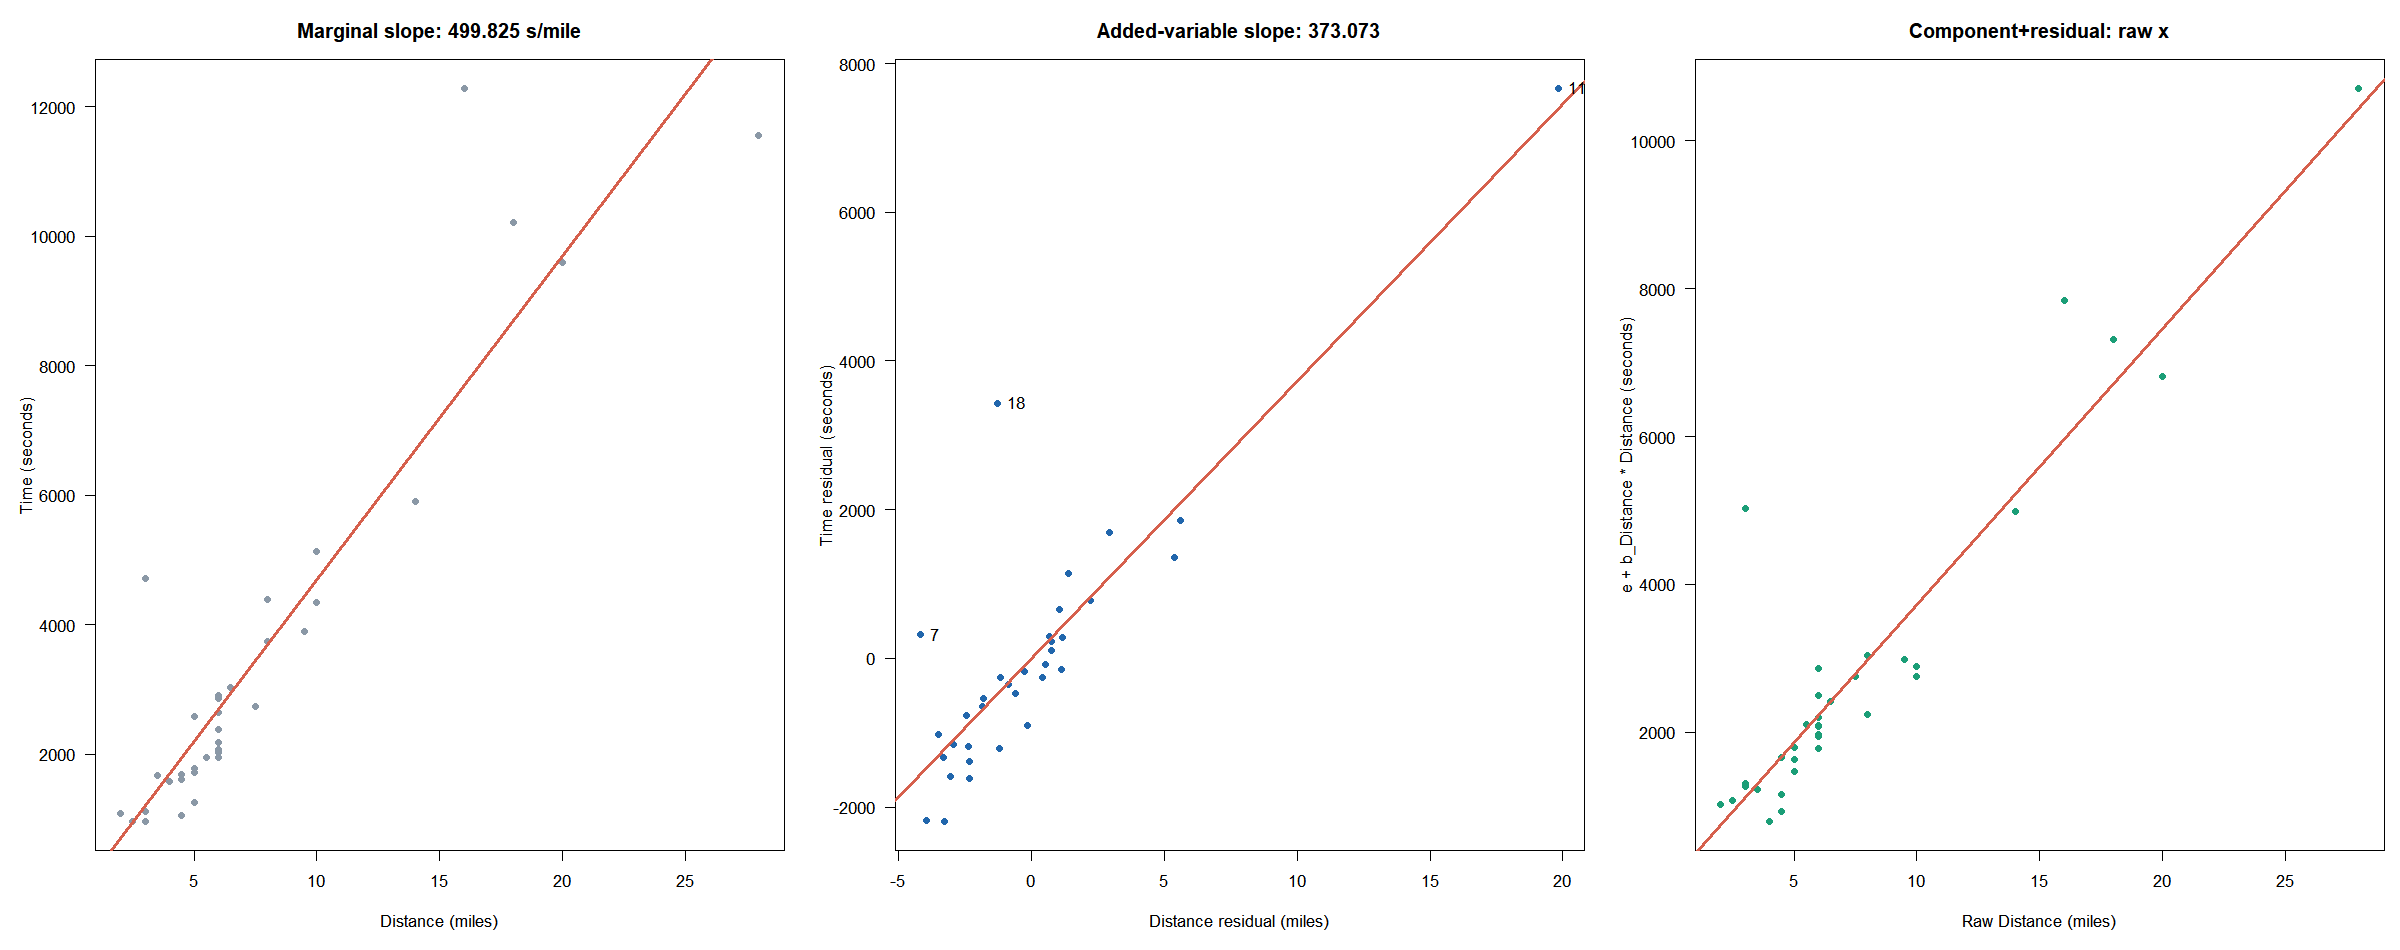

교재 5장의 개념을 표시된 교육용/공식 자료로 직접 재계산해 그린 그림입니다. [고정 버전 원본](https://github.com/lunalab-ai/regre/blob/2026-fall-w09b/course/notion/w09b/images/w09b-distance-effects.png).

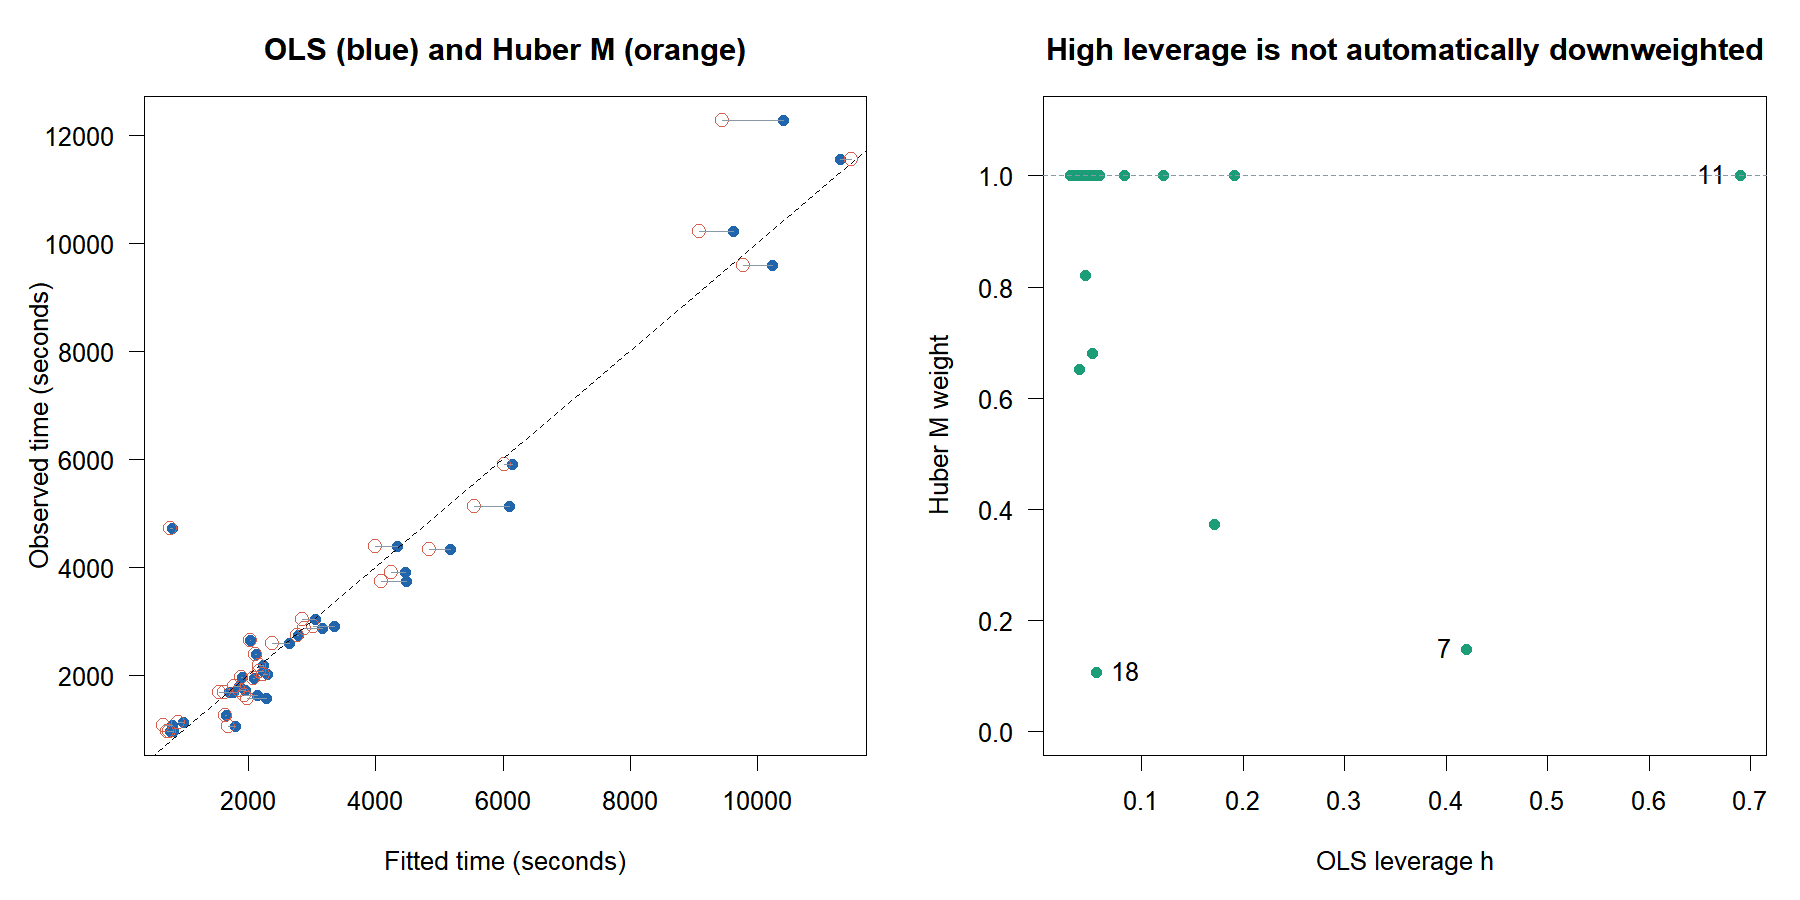

교재 5장의 개념을 표시된 교육용/공식 자료로 직접 재계산해 그린 그림입니다. [고정 버전 원본](https://github.com/lunalab-ai/regre/blob/2026-fall-w09b/course/notion/w09b/images/w09b-robust.png).

## 0. 독립 실행 준비

데이터 업로드·API 키가 필요 없습니다. 로컬 R/QMD는 data 폴더를 함께 두고, R Colab은 고정 버전의 필요한 파일만 자동 준비합니다.

In [ ]:
tag <- "2026-fall-w09b"
local_dirs <- c("data","labs/student/w09b/data","../../labs/student/w09b/data","../../../labs/student/w09b/data")
found <- local_dirs[file.exists(file.path(local_dirs,"diagnostics-influence.R"))]
data_dir <- if(length(found)) found[1] else file.path(path.expand("~"),".cache","regre",tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
expected <- c("diagnostics-base-w09b.R"="1d6d198179eb52922e0b7da3a3836838","diagnostics-influence.R"="106f87499e0a0565f4c19d75b7e26c9a","diagnostics-effects.R"="df333742f83c7f635427673c62acf214","hand-six-w09b.csv"="313e3e377db6f34c55963371366bcfe1","nyrivers-w09b.csv"="6f67635643fbb5aac0b37b7a8fed0d26","scottish-hills-w09b.csv"="ea6e5b9206884d205cfa393d89e0f84a")
paths <- c("diagnostics-base-w09b.R"="src/diagnostics.R","diagnostics-influence.R"="src/diagnostics-influence.R","diagnostics-effects.R"="src/diagnostics-effects.R","hand-six-w09b.csv"="data/sample/w09b/hand-six-w09b.csv","nyrivers-w09b.csv"="data/sample/w09b/nyrivers-w09b.csv","scottish-hills-w09b.csv"="data/sample/w09b/scottish-hills-w09b.csv")
options(timeout=120)
for(name in names(paths)) {
  target <- file.path(data_dir,name)
  if(!file.exists(target)) {
    address <- paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/",paths[[name]])
    status <- download.file(address,target,mode="wb")
    if(status!=0) stop("다운로드 실패: 인터넷 연결을 확인하고 준비 셀을 다시 실행하세요.")
    cat(name,": fixed-tag first download\n")
  } else cat(name,": bundled file or cache verified\n")
  if(unname(tools::md5sum(target))!=expected[[name]]) stop("파일 동일성 불일치: 수정 파일을 보존하고 별도 폴더에서 고정 버전을 다시 준비하세요.")
}
source(file.path(data_dir,"diagnostics-base-w09b.R"),encoding="UTF-8")
source(file.path(data_dir,"diagnostics-influence.R"),encoding="UTF-8")
source(file.path(data_dir,"diagnostics-effects.R"),encoding="UTF-8")
toy <- read.csv(file.path(data_dir,"hand-six-w09b.csv"))
ny <- read.csv(file.path(data_dir,"nyrivers-w09b.csv"))
hills <- read.csv(file.path(data_dir,"scottish-hills-w09b.csv"))
fit_review <- lm(rating~complaints+learning,data=datasets::attitude)
fit_toy <- lm(y~x,data=toy)
fit_ny_simple <- lm(Nitrogen~ComIndl,data=ny)
fit_ny_full <- lm(Nitrogen~Agr+Forest+Rsdntial+ComIndl,data=ny)
fit_hills <- lm(Time~Distance+Climb,data=hills)
toy_influence <- diag_influence(fit_toy)
ny_influence <- diag_influence(fit_ny_simple)
av_distance <- diag_added_variable(fit_hills,"Distance")
cpr_distance <- diag_component_residual(fit_hills,"Distance")
cat(R.version.string,"\nRows: six=",nrow(toy)," NY=",nrow(ny)," Hills=",nrow(hills),"\n")

## 3. 양쪽 잔차화와 성분잔차

E07–E08: 경주 전체모형의 같은 35행, Time 초/Distance 마일/Climb 피트입니다. 첨가변수와 성분잔차의 x축을 구별합니다.

In [ ]:
coef(fit_hills)
rx <- residuals(lm(Distance~Climb,data=hills))
ry <- residuals(lm(Time~Climb,data=hills))
c(AV_slope=sum(rx*ry)/sum(rx^2),full_coefficient=coef(fit_hills)["Distance"])
head(av_distance$data)
cpr_distance[1,]
plot(av_distance$data$x_residual,av_distance$data$y_residual,pch=19,
 xlab="Distance residual (miles)",ylab="Time residual (seconds)",col="#2166AC")
abline(a=0,b=av_distance$slope,col="#D6604D",lwd=2)

### L04 · Climb의 첨가변수 기울기 — 필수

공식 경주 35행의 `Time ~ Distance + Climb`을 사용합니다. Climb의 효과를 보려면 Climb과 Time 양쪽에서 절편·Distance의 선형 부분을 제거합니다. 그 잔차를 각각 $u,v$라 할 때 $\sum u^2\approx51203719.8608$, $\sum uv\approx33942330.9833$입니다. 기울기를 계산하고 단위를 쓰세요. 두 보조 회귀의 식과 첨가변수도의 두 축도 적으세요.

**힌트:** 한쪽만 잔차화하지 않습니다. 같은 35행과 같은 보조 설명변수를 사용합니다.

**자가 점검:** 전체 모형의 관심 계수와 비교합니다. Climb은 피트이며 경사각이 아닙니다.

In [ ]:
# L04: 같은 관측과 단위를 확인한 뒤 계산하세요.
# your_calculation <- ...

### L05 · 둘째 경주의 성분잔차 — 필수

둘째 경주 Carnethy는 Time 2901초, Distance 6마일, Climb 2500피트입니다. 전체 적합식은 $\widehat{\mathrm{Time}}=-539.482907+373.072677\mathrm{Distance}+0.662888\mathrm{Climb}$입니다. 적합값과 잔차를 먼저 구하고, Distance의 성분잔차와 그림의 좌표를 계산하세요. 성분잔차가 실제 완주 시간과 다른 이유도 설명하세요.

**힌트:** $c=e+b_{\mathrm{Distance}}\mathrm{Distance}$. 전체 적합값을 성분잔차로 대신하지 않습니다.

**자가 점검:** 가로축은 원래 Distance입니다. 세로축의 단위는 초입니다. 마지막 검산은 반올림하지 않은 R 계수로 합니다.

In [ ]:
# L05: 같은 관측과 단위를 확인한 뒤 계산하세요.
# your_calculation <- ...

## 4. 변수 추가와 로버스트 비교

E09–E10: 가중치와 OLS 지레값은 다른 양입니다. rlm을 OLS 전용 공통 함수에 넣지 않습니다. 일반 lm t/F 추론으로 바꾸지 않습니다.

In [ ]:
if(!requireNamespace("MASS",quietly=TRUE)) stop("MASS 패키지가 필요합니다. 브라우저는 로딩 완료를 기다리고, 데스크톱은 준비 안내를 확인하세요.")
fit_hills_robust <- MASS::rlm(Time~Distance+Climb,data=hills)
cbind(OLS=coef(fit_hills),Huber_M=coef(fit_hills_robust))
data.frame(row=c(7,11,18),h=hatvalues(fit_hills)[c(7,11,18)],weight=fit_hills_robust$w[c(7,11,18)])
list(converged=fit_hills_robust$converged,residual_df=fit_hills_robust$df.residual)
c(Distance_only=coef(lm(Time~Distance,data=hills))["Distance"],Distance_adjusted=coef(fit_hills)["Distance"])

## 5. 누적 앱에서 출력 연결

[Shiny 코드 편집기](https://lunalab-ai.github.io/regre/apps/w09b/edit/index.html)를 엽니다. 입력→함수→표/그림을 추적하고 마지막에 CSV·편집 R 코드를 내려받습니다.

### L06 · 앱의 출력 연결 하나 바꾸기 — 필수

누적 Shiny 편집기의 `W09B_L06` 표식을 찾습니다. 선택한 강의 요약 출력은 현재 지레값을 표시합니다. 같은 관측 선택 입력을 유지하면서 이 출력을 DFFITS와 그에 맞는 라벨로 바꾸세요. 기본 모형은 NY 단순모형입니다. 4번과 5번을 차례로 선택하고 방향·크기를 설명하세요.

**힌트:** 입력 `w9_row` → `diag_influence()`가 만든 표 → `output$w9_selected` 순서로 따라갑니다. 계산 함수를 통째로 다시 만들지 않습니다.

**자가 점검:** 라벨과 값의 정의가 맞아야 합니다. Run 후 두 관측에서 결과가 달라지는지 확인하고 CSV·R 코드를 내려받습니다. 원상 복구 후 처음부터 실행합니다.

In [ ]:
# L06: 편집기에서 W09B_L06 표식을 찾아 출력 연결 한 곳을 수정합니다.
# 수정 전 예상, 수정한 필드와 라벨, 두 관측의 실제 출력을 기록하세요.

## L10 · 새 변수 추가의 네 상황 — 확장

다음은 추가 구성한 판단 상황입니다. 새 변수의 계수 p값이 0.42이고, 기존 주요 계수 추정값은 0.8에서 2.6으로 바뀌며 표준오차도 커졌습니다. 교재 A–D의 어느 상황을 우선 검토할지 쓰고, 공선성·연구 목적과 관련해 무엇을 더 조사할지 설명하세요. 이 숫자만으로 새 변수를 자동 삭제하거나 인과를 주장할 수 있는지도 판단하세요.

힌트: 새 계수의 유의성과 기존 계수의 변화를 두 칸으로 분리합니다. 자가 점검: 경우의 문자만 쓰지 않고 추가 확인을 남깁니다.

In [ ]:
# L10: 식/코드와 해석을 직접 작성하세요.
# your_check <- ...

## L11 · Huber 가중치의 의미 — 확장

같은 경주 Huber M 적합에서 11번의 OLS 지레값은 약 0.689816, 가중치는 1이고, 18번은 지레값 약 0.055355, 가중치 약 0.106648입니다. 두 결과가 모순인지 설명하고, 로버스트 회귀와 OLS의 로버스트 표준오차를 구별하세요. `rlm`의 `df.residual=NA`를 일반 `lm` t/F로 바꾸어 읽으면 안 되는 이유도 적으세요.

힌트: 이번 M 가중치는 잔차에 기초합니다. 자가 점검: 모든 로버스트 방법을 같은 방식으로 일반화하지 않습니다.

In [ ]:
# L11: 식/코드와 해석을 직접 작성하세요.
# your_check <- ...

## L12 · 정의되지 않는 진단과 기록 — 확장

추가 구성 자료 $x=(0,0,0,0,0,1)$, $y=(1,3,2,5,4,7)$에 절편 포함 `y ~ x`를 적합합니다. 마지막 관측의 $h$를 확인하고 이를 제외했을 때 설계행렬의 순위가 어떻게 되는지 조사하세요. 어떤 진단을 정상 숫자로 보고하면 안 되는지, `NA`를 0으로 바꾸면 왜 잘못인지 설명하세요.

힌트: 마지막 행을 제외하면 $x$의 독립 변동이 남는지 확인합니다. 자가 점검: 원자료는 보존하고 상태 메시지를 함께 기록합니다.

In [ ]:
# L12: 식/코드와 해석을 직접 작성하세요.
# your_check <- ...

## 변수 효과 실행 자가 검사

In [ ]:
stopifnot(nrow(hills)==35,df.residual(fit_hills)==32,hills$Time[23]==2859,
 abs(av_distance$slope-coef(fit_hills)["Distance"])<1e-8,
 max(abs(cpr_distance$component_residual-residuals(fit_hills)-coef(fit_hills)["Distance"]*hills$Distance))<1e-8,
 fit_hills_robust$converged,length(fit_hills_robust$w)==35,is.na(fit_hills_robust$df.residual))
cat("W09B_EFFECTS_RUNTIME_CHECK_PASSED\n")